# 4장 1강 · 이미지 임베딩과 특징 표현

실습파일  |  Oxford-IIIT Pet · ResNet18

비글 사진 한 장을 입력하면 어떤 사진을 첫 번째로 보여 주어야 할까요? 이 실습에서는 같은 사진을 픽셀과 임베딩으로 각각 표현하고, 검색 기준을 바꾸었을 때 실제로 어떤 사진이 1위에 오는지 확인합니다.

## 실습 안내

| 구간 | 풀어 볼 질문 | 산출물 |
|---|---|---|
| 필수 1 | 해상도가 다른 사진이 어떻게 길이 512인 벡터가 될까? | 전처리 검산, 층별 출력, ID와 특징값 표 |
| 필수 2 | 코사인 유사도와 유클리드 거리는 언제 같은 순위를 만들까? | 손계산, 실제 순위 역전, 단위 벡터 검증 |
| 과제 1 | 이 표현은 품종 검색과 분류에 얼마나 도움이 될까? | 검색 성적표, 학습한 분류기, 오답 사례 해석 |

**준비물**  강의에 제공된 Oxford ZIP을 압축 상태로 노트북과 같은 폴더에 둡니다. 루트에 `metadata.csv`가 있고 `image_path` 열이 ZIP 내부 사진 경로를 가리키는 배포본을 사용합니다. 파일 이름이 다르면 아래 `paths`를 수정하세요. Python과 Jupyter, NumPy, pandas, Pillow, 서로 호환되는 PyTorch와 torchvision이 필요합니다. 검증 환경은 CPU용 PyTorch 2.6과 torchvision 0.21입니다. ResNet18 기본 가중치는 첫 실행 때 내려받으며, 이후에는 PyTorch 캐시를 사용합니다.

**실행 순서**  공통 준비 ①~③을 먼저 실행합니다. 필수 1, 필수 2, 과제 1은 각각 공통 준비 직후부터 시작할 수 있습니다. 각 구간 안에서는 번호순으로 진행하세요. 표에서 ID 하나는 사진 한 장을 뜻합니다. 점수를 반올림하는 작업은 화면에 표시할 때만 합니다.

### 공통 준비 ① · 어떤 사진을 어디에 쓸까?

8개 품종에서 검색 후보(갤러리) 8장씩, 검색을 요청할 사진(질의) 6장씩을 뽑습니다. 분류기 학습용으로는 품종당 12장을 따로 뽑습니다. 고정 예제 7장을 더하면 총 215장입니다. 배포본의 `val` 중 96장은 이 수업의 분류기 학습용, `test` 중 112장은 갤러리와 질의용입니다. 이 실험에서는 별도 하이퍼파라미터 탐색을 하지 않습니다.

`metadata.csv`의 모든 행에 원본 사진이 들어 있는 것은 아니므로, ZIP 안에 실물이 있는 행만 사용합니다. 정렬한 뒤 고정 난수로 비복원 추출하고 파일 ID와 RGB 내용 중복을 검사합니다. `photos[id]`는 원본 사진, `pos[id]`는 아래 특징 행렬에서 그 사진이 놓일 행 번호입니다.

In [11]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import hashlib
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display

torch.set_num_threads(2)
SEED = 42
paths = [Path("C:/Users/jihun/OneDrive/Desktop/DS 실습자료/LV2/이미지 분석/DATA/1장, 2장(1,2),3장(1),4장/Oxford/oxford_dataset/oxford_dataset.zip")]
data_path = next((p for p in paths if p.is_file()),None)
if data_path is None:
    raise FileNotFoundError("Oxford ZIP을 노트북 옆에 두거나 paths에 실제 경로를 넣으세요.")
breeds = ["beagle","pug","boxer","shiba_inu","Persian","Birman","Ragdoll","Siamese"]
example_ids = ["beagle_110","beagle_111","Persian_100"]
pug_ids = ["pug_100","pug_103","beagle_117","Persian_125"]
demo_ids = example_ids + pug_ids
with ZipFile(data_path) as z:
    meta = pd.read_csv(z.open("metadata.csv")).set_index("image_id")
    meta = meta.loc[meta.image_path.isin(z.namelist()) & meta.class_name.isin(breeds)].sort_index()
rng = np.random.default_rng(SEED)
train_ids, gallery_ids, query_ids = [], [], []
for name in breeds:
    subset = meta[meta.class_name == name]
    pool = subset[(subset.split == "val") & ~subset.index.isin(demo_ids)].index
    train_ids.extend(rng.choice(pool,12,replace=False).tolist())
    chosen = rng.choice(subset[subset.split=="test"].index,14,replace=False).tolist()
    gallery_ids.extend(chosen[:8])
    query_ids.extend(chosen[8:])
all_ids = demo_ids + train_ids + gallery_ids + query_ids
assert len(all_ids) == len(set(all_ids))
photos, hashes = {}, []
with ZipFile(data_path) as z:
    for key in all_ids:
        with Image.open(BytesIO(z.read(meta.loc[key,"image_path"]))) as source:
            im = source.convert("RGB")
        photos[key] = im
        digest = hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest()
        hashes.append(digest)
assert len(set(hashes))==len(all_ids), "크기와 RGB 값이 동일한 사진이 있습니다."
pos = {key:i for i,key in enumerate(all_ids)}

def show_photos(ids):
    sheet = Image.new("RGB",(185*len(ids),180),"white")
    pen = ImageDraw.Draw(sheet)
    for i,key in enumerate(ids):
        im = ImageOps.contain(photos[key],(180,145))
        sheet.paste(im,(185*i+(180-im.width)//2,0))
        pen.text((185*i+3,150),key,fill="black")
    display(sheet)
print("예제 / 분류기 학습 / 검색 후보 / 질의",*[len(g) for g in [demo_ids,train_ids,gallery_ids,query_ids]])

예제 / 분류기 학습 / 검색 후보 / 질의 7 96 64 48


### 공통 준비 ② · 같은 사진에서 두 표현 만들기

`weights.transforms()`는 해당 가중치의 전처리 순서를 가져옵니다. 사진들을 같은 크기로 준비하고 16장 이하로 모아 모델에 넣습니다. `encoder.eval()`은 모델의 배치 정규화 층이 학습 때 저장한 통계를 쓰게 합니다. `inference_mode()`는 특징 추출 중 기울기 기록을 생략합니다. 원래 분류층은 비교를 위해 `original_fc`에 보관합니다.

`E`의 한 행은 512개 모델 특징입니다. `P`의 한 행은 같은 전처리 영상을 16×16으로 평균 축소해 펼친 768개 RGB 값입니다. `pick(E, ids)`는 주어진 ID 순서대로 행을 꺼내고, `unit`은 각 행을 그 행의 길이로 나눕니다. 뒤 문항에서 이 변환을 수치로 검산합니다.

In [12]:
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
encoder = resnet18(weights=weights).eval()
original_fc = encoder.fc
encoder.fc = nn.Identity()
encoder.requires_grad_(False)

def extract(ids):
    embedded, pixels = [], []
    with torch.inference_mode():
        for start in range(0,len(ids),16):
            batch = torch.stack([preprocess(photos[key]) for key in ids[start:start+16]])
            embedded.append(encoder(batch).cpu().numpy())
            # 같은 크롭·같은 정규화에서 RGB만 16×16으로 평균 축소한 비교 기준
            pooled = nn.functional.adaptive_avg_pool2d(batch,(16,16))
            pixels.append(pooled.flatten(1).numpy())
    return np.concatenate(embedded), np.concatenate(pixels)

E, P = extract(all_ids)
def pick(matrix,ids):
    return matrix[[pos[k] for k in ids]]
def unit(x):
    lengths = np.linalg.norm(x,axis=1,keepdims=True)
    if np.any(lengths==0):
        raise ValueError("길이가 0인 행은 코사인 비교를 할 수 없습니다.")
    return x/lengths
print("RGB 픽셀 특징",P.shape,"ResNet 임베딩",E.shape)

RGB 픽셀 특징 (215, 768) ResNet 임베딩 (215, 512)


### 공통 준비 ③ · 검색과 채점 도구

`neighbors(특징행렬, 질의ID목록, 후보ID목록, 기준)`은 점수표와 순위 인덱스를 반환합니다. 점수표의 행은 질의, 열은 후보입니다. 순위 인덱스의 첫 열은 각 질의에서 이긴 **후보의 열 번호**입니다. 코사인은 큰 값부터, 거리는 작은 값부터 정렬합니다. 같은 값이면 원래 후보 순서를 유지합니다. `eval_ranks`는 완성된 순위에 품종 라벨을 붙여 채점합니다. 같은 품종을 관련 사진으로 정의하는 수업용 기준입니다.

In [13]:
def neighbors(matrix, queries, gallery, metric="cosine"):
    q = pick(matrix,queries).astype(np.float64)
    g = pick(matrix,gallery).astype(np.float64)
    if metric=="cosine":
        values = unit(q) @ unit(g).T
        order = np.argsort(-values,axis=1,kind="stable")
    elif metric=="euclidean":
        values = np.stack([np.linalg.norm(g-v,axis=1) for v in q])
        order = np.argsort(values,axis=1,kind="stable")
    else:
        raise ValueError(metric)
    return values, order

def eval_ranks(order,queries,gallery):
    # 품종 라벨은 순위 결정이 끝난 뒤에 사용합니다.
    relevance = meta.loc[gallery,"class_name"].to_numpy()[order] == meta.loc[queries,"class_name"].to_numpy()[:,None]
    return pd.DataFrame({"query":queries, "breed":meta.loc[queries,"class_name"].to_numpy(),
                         "top1":np.array(gallery)[order[:,0]], "hit1":relevance[:,0],
                         "hit3":relevance[:,:3].any(axis=1),
                         "correct_in3":relevance[:,:3].sum(axis=1)})

## 필수 1 · 원본 사진에서 512차원 임베딩까지

비글 두 장과 페르시안 한 장을 따라갑니다. 행은 어떤 사진인지, 열은 어떤 종류의 수치인지 구분해 설명하세요.

### 1-1. 원본과 모델 입력의 픽셀 대조

예제 3장의 원본, 품종과 가로·세로 크기를 확인하세요. 권장 전처리로 배치를 만들고 첫 사진의 중심 크롭에서 왼쪽 위 픽셀의 빨간 채널을 직접 표준화해 모델 입력과 비교하세요. 원본과 크롭에서 같은 좌표가 같은 지점을 뜻하는지도 설명하세요.

**풀이 힌트**  
`preprocess.resize_size`와 `crop_size`를 확인하고 torchvision의 resize, center_crop을 순서대로 사용합니다. 8비트 값을 255로 나눈 뒤 빨간 채널의 평균과 표준편차를 적용하세요.

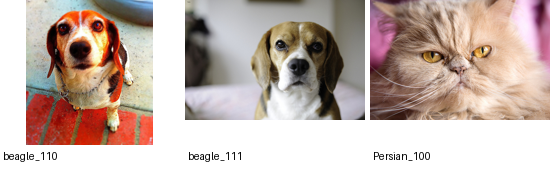

beagle_110 beagle 원본 (가로, 세로) (437, 500)
beagle_111 beagle 원본 (가로, 세로) (500, 333)
Persian_100 Persian 원본 (가로, 세로) (500, 334)
리사이즈 / 크롭 (256, 292) (224, 224) 배치 (3, 3, 224, 224)
R 원값, 손계산, 모델 입력 223 1.700916 1.700916


In [14]:
# 여기에 풀이를 작성하세요.
# 1-1 · 원본과 모델 입력의 픽셀 대조
from torchvision.transforms import functional as F   # resize·center_crop 같은 변환을 함수로 직접 부를 수 있는 모듈
show_photos(example_ids)                      # 예제 3장(beagle_110, beagle_111, Persian_100)을 나란히 표시
for key in example_ids:
    print(key, meta.loc[key,"class_name"], "원본 (가로, 세로)", photos[key].size)
    # meta.loc[ID, 열]: 그 사진의 품종 / PIL의 .size는 (가로, 세로) 순서임 (numpy shape와 반대)
batch = torch.stack([preprocess(photos[key]) for key in example_ids])
# preprocess: 가중치가 권장하는 전처리 (리사이즈 → 중심 크롭 → 0~1 변환 → 표준화)
# 사진마다 (3, 224, 224) 텐서가 되고, torch.stack으로 쌓아 (사진 3, 채널 3, 세로 224, 가로 224)
resized = F.resize(photos[example_ids[0]], preprocess.resize_size, interpolation=preprocess.interpolation)
# 첫 사진(beagle_110)만 같은 과정을 손으로 따라 함
# ① 짧은 변을 resize_size(256)로 맞춤 (가로세로 비율은 유지) → 437×500이 256×292가 됨
crop = F.center_crop(resized, preprocess.crop_size)   # ② 가운데 224×224 영역만 잘라 냄
red = crop.getpixel((0,0))[0]                 # 크롭의 왼쪽 위 (x=0, y=0) 픽셀 (R, G, B) 중 [0] = 빨간 값 → 223
manual = (red / 255 - preprocess.mean[0]) / preprocess.std[0]
# ③ 255로 나눠 0~1로 바꾸고 ④ 빨간 채널 평균(0.485)을 뺀 뒤 표준편차(0.229)로 나눔 = 표준화
print("리사이즈 / 크롭", resized.size, crop.size, "배치", tuple(batch.shape))
# → (256, 292) (224, 224) 배치 (3, 3, 224, 224)
print("R 원값, 손계산, 모델 입력", red, round(manual,6), round(batch[0,0,0,0].item(),6))
# batch[0,0,0,0] = [사진 0, 채널 0(R), 행 0, 열 0] / .item(): 텐서 한 칸 → 파이썬 숫자
# → 223 1.700916 1.700916 (손계산과 모델 입력이 같음)
assert abs(manual - batch[0,0,0,0].item()) < 0.00001
# 두 값의 차이가 0.00001보다 작은지 확인 (아니면 오류를 내고 멈춤)

#### 1-1 정답 및 해설

**코드의 종합적인 수행 과정**

1. `size`는 (가로, 세로)입니다. 첫 비글은 437×500인 세로 사진이고 두 번째는 500×333인 가로 사진입니다. 원본 그대로는 두 배열의 가로·세로가 달라 한 배치로 쌓을 수 없습니다.
2. 짧은 변을 256으로 맞추며 비율을 유지한 다음 가운데 224×224 영역을 잘라 냅니다. `crop.getpixel((0,0))[0]`은 이 영역의 왼쪽 위에서 빨간 채널 하나를 꺼냅니다.
3. 정수 픽셀을 255로 나누면 0~1이 됩니다. 여기서 빨간 채널 평균 0.485를 빼고 표준편차 0.229로 나눕니다. 마지막 줄은 같은 위치를 실제 전처리 텐서에서 찾아 오차가 0.00001보다 작은지 확인합니다.

**결과 해설**

첫 비글은 256×292로 리사이즈된 뒤 224×224가 되었습니다. 크롭 왼쪽 위의 빨간 채널은 223입니다. (223÷255−0.485)÷0.229 ≈ 1.700916으로, 실제 모델 입력과 소수점 여섯 자리까지 같습니다. 배치 (3, 3, 224, 224)의 첫 3은 사진 수, 두 번째 3은 RGB 채널 수입니다. 두 표준화 값이 같은 것은 손계산과 전처리가 이 위치에서 일치한다는 뜻입니다. 표준화 값이 음수여도 정상입니다. 해당 채널 값이 기준 평균보다 낮으면 음수가 됩니다.

**서술형 답안 예시**

모델은 세 사진 모두에서 224×224 영역을 봅니다. 원본을 축소하고 중심을 잘랐으므로 크롭의 (0, 0)은 원본의 왼쪽 위 픽셀과 위치가 달라질 수 있습니다.

### 1-2. 특징 맵에서 512개 숫자가 만들어지는 지점

같은 배치를 ResNet18의 마지막 합성곱 블록, 평균 풀링, 평탄화, 분류층 순서로 추적하세요. 첫 사진·첫 채널의 7×7 평균을 직접 구하고, 저장해 둔 특징과 원래 분류층을 적용한 출력의 모양도 확인하세요.

**풀이 힌트**  
`list(encoder.children())[:-2]`는 마지막 풀링과 fc 앞까지의 층을 가져옵니다. `flatten(1)`은 사진 축을 남깁니다.

In [15]:
# 여기에 풀이를 작성하세요.
# 1-2 · 특징 맵에서 512개 숫자가 만들어지는 지점
with torch.inference_mode():                  # 기울기 기록 없이 계산만 함 (학습이 아니므로 더 빠르고 메모리 절약)
    maps = nn.Sequential(*list(encoder.children())[:-2])(batch)
    # encoder.children(): ResNet18의 층들을 순서대로 꺼냄
    # [:-2]: 마지막 두 층(avgpool, fc)을 뺀 나머지 = 마지막 합성곱 블록까지
    # nn.Sequential(*목록): 그 층들을 차례로 통과시키는 모델로 묶고, 바로 batch를 넣음
    # → maps 모양 (3, 512, 7, 7) = (사진, 채널, 세로, 가로)
    pooled = encoder.avgpool(maps)            # 채널마다 7×7 = 49칸의 평균 → (3, 512, 1, 1)
    vectors = encoder.fc(pooled.flatten(1))
    # flatten(1): 0번 축(사진)은 두고 나머지 축을 한 줄로 폄 → (3, 512)
    # encoder.fc는 공통 준비에서 Identity로 바꿔 둠 → 값을 그대로 통과 = 512차원 임베딩
    original_scores = original_fc(vectors)    # 보관해 둔 원래 분류층(Linear 512→1000) 적용 → ImageNet 1000개 클래스 점수
print("기존 층 / 교체한 층", original_fc, encoder.fc)
print("특징 맵 → 풀링 → 임베딩 → 기존 분류 점수")
print([tuple(t.shape) for t in (maps, pooled, vectors, original_scores)])
# 네 텐서의 모양 → [(3, 512, 7, 7), (3, 512, 1, 1), (3, 512), (3, 1000)]
print("49칸 평균과 0번 특징", maps[0,0].mean().item(), vectors[0,0].item())
# maps[0,0] = 첫 사진·0번 채널의 7×7 지도 → 직접 평균한 값과 임베딩 0번 값이 같음 (둘 다 약 0.59612)
print("저장한 E와 일치", np.allclose(vectors.numpy(), pick(E,example_ids), atol=1e-5))
# pick(E, ID 목록): 공통 준비에서 미리 뽑아 둔 임베딩 행렬 E에서 같은 사진들의 행을 꺼냄
# np.allclose: 모든 값이 오차 1e-5 안에서 같으면 True

기존 층 / 교체한 층 Linear(in_features=512, out_features=1000, bias=True) Identity()
특징 맵 → 풀링 → 임베딩 → 기존 분류 점수
[(3, 512, 7, 7), (3, 512, 1, 1), (3, 512), (3, 1000)]
49칸 평균과 0번 특징 0.5961214303970337 0.5961214303970337
저장한 E와 일치 True


#### 1-2 정답 및 해설

**코드의 종합적인 수행 과정**

1. 마지막 합성곱 블록까지 통과하면 각 사진에 대해 512장의 작은 특징 지도가 생깁니다. 지도 한 장의 가로·세로는 각각 7입니다. 한 칸은 입력에서 그 위치 주변에 대한 모델의 반응을 담습니다.
2. 평균 풀링은 채널별로 49개 값을 더해 49로 나눕니다. 그래서 (3, 512, 7, 7)이 (3, 512, 1, 1)이 됩니다. 서로 다른 채널끼리는 평균내지 않습니다.
3. 평탄화는 뒤쪽 세 축을 한 축으로 펴고, Identity 층은 받은 값을 그대로 돌려줍니다. 따로 보관한 기존 Linear 층까지 적용하면 같은 512개 특징에서 ImageNet의 1,000개 분류 점수가 나옵니다.

**결과 해설**

첫 비글의 0번 지도 평균은 약 0.59612이고 임베딩의 0번 값과 같습니다. (3, 512)에서 한 행은 사진 한 장입니다. (3, 1000)은 기존 분류기의 클래스별 점수입니다. 두 출력은 같은 사진에서 시작하지만 열의 의미가 다릅니다.

**서술형 답안 예시**

평균 풀링을 거치면서 채널별 공간 반응이 하나의 수로 요약됐습니다. 분류층 앞의 512개 값을 보관하면 원래의 1,000개 클래스 밖에서도 사진 간 유사도를 계산할 수 있습니다.

### 1-3. 행 순서가 바뀌어도 사진의 특징을 찾을 수 있을까?

사진을 역순으로 다시 인코딩하고 ID별 첫 다섯 특징을 표로 표시하세요. 원래 순서의 행과 바로 비교한 결과, ID로 맞춘 결과를 각각 검산하세요.

**풀이 힌트**  
`example_ids[::-1]`는 역순 목록입니다. `pick`을 호출할 때 그 목록을 넘기면 기존 행렬에서도 같은 순서로 꺼낼 수 있습니다.

In [16]:
# 여기에 풀이를 작성하세요.
# 1-3 · 행 순서가 바뀌어도 사진의 특징을 찾을 수 있을까?
reverse_ids = example_ids[::-1]               # [::-1] = 목록을 거꾸로 → [Persian_100, beagle_111, beagle_110]
rev_E, _ = extract(reverse_ids)
# 역순 목록으로 임베딩을 다시 추출함 (두 번째 반환값인 픽셀 특징은 안 쓰므로 _)
# rev_E 모양 (3, 512): i번째 행 = reverse_ids[i] 사진의 특징
display(pd.DataFrame(rev_E[:,:5], index=reverse_ids, columns=[f"특징 {j}" for j in range(5)]).round(4))
# rev_E[:,:5]: 모든 행(사진), 앞 5개 열(특징 0~4) / 행 이름 = 사진 ID, 열 이름 = "특징 0"~"특징 4"
print("원래 순서와 비교", np.allclose(rev_E,pick(E,example_ids),atol=1e-5))
# 행 번호끼리 비교 → 0행끼리 Persian과 beagle을 비교하게 되므로 False
print("같은 ID 순서로 비교", np.allclose(rev_E,pick(E,reverse_ids),atol=1e-5))
# E에서도 역순 ID로 꺼내 같은 사진끼리 비교 → True (행 번호가 아니라 ID로 맞춰야 함)

,특징 0,특징 1,특징 2,특징 3,특징 4
Persian_100,0.5586,0.8054,4.0726,1.0931,0.0227
beagle_111,1.3458,1.1310,0.7133,0.1668,1.1347
beagle_110,0.5961,1.7446,0.6655,1.0984,3.3580


원래 순서와 비교 False
같은 ID 순서로 비교 True


#### 1-3 정답 및 해설

**코드의 종합적인 수행 과정**

1. 역순 목록의 첫 사진은 Persian_100입니다. `extract`는 전달받은 순서로 이미지들을 쌓고 같은 순서로 결과를 반환합니다.
2. `[:,:5]`는 모든 사진의 앞 다섯 열을 보여 줍니다. 표의 행 이름으로 역순 ID를 붙입니다. 검산은 표에 보이는 다섯 개뿐 아니라 512개 전체로 수행합니다.
3. `np.allclose`는 같은 위치의 값이 작은 반올림 오차 안에서 모두 같은지 검사합니다. 첫 비교는 0행의 페르시안을 원래 0행의 비글과 대조합니다. 두 번째 비교는 양쪽의 0행 모두 페르시안입니다.

**결과 해설**

첫 결과는 False, 두 번째는 True입니다. 예를 들어 0번 특징이 약 0.5586인 행은 역순 표에서 첫 행이지만 원래 표에서는 마지막 행입니다. 행 번호만으로 품종을 붙이면 다른 사진의 결과를 해석할 수 있습니다.

**서술형 답안 예시**

파일 ID를 따라 행을 다시 맞추자 특징이 일치했습니다. 검색 결과의 열 번호도 같은 방식으로 갤러리 ID로 변환해야 실제 사진을 찾을 수 있습니다.

### 1-4. 특징 한 개가 비슷하면 같은 품종일까?

beagle_110과 나머지 두 사진을 비교하세요. 0번 특징의 절댓값 차이와 512개 전체의 코사인 유사도를 나란히 구하고, 각각 어느 사진을 고르는지 설명하세요.

**풀이 힌트**  
차이는 0에 가까울수록, 코사인은 클수록 가깝습니다. `neighbors`의 첫 반환값은 입력 후보 순서에 대응합니다.

In [17]:
# 여기에 풀이를 작성하세요.
# 1-4 · 특징 한 개가 비슷하면 같은 품종일까?
others = example_ids[1:]                      # 기준 사진(beagle_110)을 뺀 나머지 2장 [beagle_111, Persian_100]
a = pick(E,[example_ids[0]])[0]               # 기준 사진의 임베딩: pick 결과 (1, 512)에서 [0] → 512개짜리 1차원 벡터
gap = abs(pick(E,others)[:,0] - a[0])
# pick(E,others)[:,0]: 후보 2장의 0번 특징만 꺼냄 / a[0]: 기준의 0번 특징
# 뺀 뒤 abs(절댓값)로 부호 없이 차이 크기만 봄 → 작을수록 가까움
sim, _ = neighbors(E,[example_ids[0]],others)
# 512개 특징 전체로 코사인 유사도를 계산함 (metric 기본값 "cosine")
# sim 모양 (질의 1, 후보 2), 열 순서 = others 순서 / 순위 인덱스는 안 쓰므로 _
display(pd.DataFrame({"0번 특징 차이":gap, "전체 코사인":sim[0]},index=others).round(5))
# sim[0] = 첫(유일한) 질의의 행
# → 0번 특징 하나로는 Persian(차이 0.0375)이 가깝지만, 전체 코사인은 beagle_111(0.758)이 더 큼

,0번 특징 차이,전체 코사인
beagle_111,0.74966,0.75839
Persian_100,0.03751,0.41283


#### 1-4 정답 및 해설

**코드의 종합적인 수행 과정**

1. 기준 벡터에서 첫 번째 원소 `a[0]`를 꺼냅니다. 후보마다 같은 번호의 원소를 꺼내 뺀 후 절댓값을 취합니다. 부호 대신 차이 크기를 보고 싶기 때문입니다.
2. 두 번째 열은 각 사진의 512개 값을 모두 쓰며, 각 벡터의 길이를 1로 맞춘 뒤 대응 성분끼리 곱해 더한 값입니다. 계산식은 필수 2에서 직접 확인합니다.

**결과 해설**

0번 특징은 기준 약 0.5961, 다른 비글 약 1.3458, 페르시안 약 0.5586입니다. 차이만 보면 페르시안(약 0.0375)이 더 가깝습니다. 전체 코사인은 비글 약 0.7584, 페르시안 약 0.4128로 순서가 바뀝니다.

**서술형 답안 예시**

0번 특징 하나로 품종을 정하면 이 예에서 페르시안을 선택합니다. 수치 하나에 ‘비글다움’ 같은 이름을 붙일 근거가 없으며, 이 비교에서는 여러 특징의 조합이 같은 품종을 찾아냈습니다.

## 필수 2 · 거리와 유사도가 바꾸는 검색 순위

코사인 유사도는 두 벡터 사이 각도의 코사인입니다. 유클리드 거리는 두 끝점 사이의 직선거리입니다. 작은 벡터로 공식을 검산하고 실제 사진에서 두 기준이 다른 이웃을 고르는 경우를 찾아보세요.

### 2-1. 두 성분으로 손계산하고 길이를 바꿔 보기

교안의 운동화 A=(1,0), 운동화 B=(0.8,0.6), 가방 C=(0,1)를 사용하세요. A에서 B와 C까지의 내적·길이·코사인·거리를 계산하고, B를 세 배로 늘리면 어느 지표의 순위가 바뀔지 예측한 뒤 확인하세요.

**풀이 힌트**  
내적은 대응 성분의 곱을 더한 값입니다. 두 벡터 길이의 곱으로 나누면 코사인이 됩니다. 거리는 성분 차이 제곱합의 제곱근입니다.

In [18]:
# 여기에 풀이를 작성하세요.
# 2-1 · 두 성분으로 손계산하고 길이를 바꿔 보기
A, B, C = np.array([1.,0.]), np.array([0.8,0.6]), np.array([0.,1.])   # 운동화 A, 운동화 B, 가방 C (성분 2개짜리 벡터)
rows = []                                     # 결과 행을 모을 빈 목록
for label,v in [("B",B),("C",C),("3B",3*B)]:  # 후보 B, C, 그리고 B를 세 배로 늘린 3B = (2.4, 1.8)
    dot = A @ v                               # @ = 내적: 같은 자리 성분끼리 곱해 더함 (A[0]×v[0] + A[1]×v[1])
    length = np.linalg.norm(v)                # 벡터 길이(노름) = √(성분 제곱의 합)
    rows.append([label,dot,length,dot/(np.linalg.norm(A)*length),np.linalg.norm(A-v)])
    # 코사인 = 내적 ÷ (A 길이 × 후보 길이) → 방향만 비교함 (길이를 늘려도 그대로)
    # 거리 = 두 벡터 차이(A−v)의 길이 → 두 끝점 사이의 직선거리
display(pd.DataFrame(rows,columns=["후보","내적","후보 길이","코사인","거리"]).round(5))
# → 3B는 코사인 0.8로 B와 같지만, 거리는 2.28로 C(1.41)보다 멀어짐 → 거리 기준 순위만 뒤집힘

,후보,내적,후보 길이,코사인,거리
0,B,0.8,1.0,0.8,0.63246
1,C,0.0,1.0,0.0,1.41421
2,3B,2.4,3.0,0.8,2.28035


#### 2-1 정답 및 해설

**코드의 종합적인 수행 과정**

1. A와 B의 내적은 1×0.8 + 0×0.6 = 0.8입니다. B의 길이는 √(0.8²+0.6²) = 1이고 A도 길이가 1이므로 코사인은 0.8입니다. 거리는 √((1−0.8)²+(0−0.6)²) = √0.4 ≈ 0.63246입니다.
2. A와 C는 직각입니다. 내적과 코사인은 0이지만 거리는 √2 ≈ 1.41421입니다. 거리 0은 두 끝점의 좌표가 모두 같을 때 나옵니다.
3. 3B=(2.4,1.8)의 내적은 2.4, 길이는 3입니다. 코사인은 2.4÷3 = 0.8, 거리는 √(1.4²+1.8²) ≈ 2.28035입니다.

**결과 해설**

B와 C 중에서는 두 지표 모두 B를 고릅니다. B 대신 3B를 놓으면 코사인은 여전히 운동화를 고르지만 유클리드 거리는 가방 C를 고릅니다. 세 배로 늘린 벡터는 원래와 같은 방향으로 더 멀리 뻗어 있습니다.

**서술형 답안 예시**

양의 상수로 벡터의 크기만 바꾸면 코사인은 유지됩니다. 원래 벡터로 잰 거리에는 벡터의 길이도 영향을 주므로 후보 순위가 뒤집힐 수 있습니다.

### 2-2. 비글 사진의 유사도를 중간값부터 계산하기

beagle_110과 나머지 예제 두 장의 내적, 양쪽 벡터 길이, 코사인, 유클리드 거리를 구하세요. 직접 계산한 값이 검색 함수의 값과 일치하는지 검산하고 1위 사진을 고르세요.

**풀이 힌트**  
벡터 길이는 제곱합의 제곱근입니다. 파일 ID로 1차원 벡터를 꺼내 사진 한 쌍씩 계산하면 중간값을 보기 쉽습니다.

In [19]:
# 여기에 풀이를 작성하세요.
# 2-2 · 비글 사진의 유사도를 중간값부터 계산하기
key, *candidates = example_ids
# 언패킹: 첫 원소 → key(beagle_110), 나머지 → candidates 목록 [beagle_111, Persian_100]
v = pick(E,[key])[0].astype("float64")        # 기준 임베딩 512개, float64로 바꿔 계산 오차를 줄임
records = []
for key2 in candidates:                       # 후보 사진 한 장씩
    w = pick(E,[key2])[0].astype("float64")   # 후보 임베딩 512개
    dot = (v*w).sum()                         # v*w: 같은 번호끼리 곱한 512개 → .sum()으로 모두 더하면 내적 하나
    nv, nw = np.linalg.norm(v), np.linalg.norm(w)   # 기준 벡터 길이, 후보 벡터 길이
    records.append([dot,nv,nw,dot/(nv*nw),np.sqrt(((v-w)**2).sum())])
    # 코사인 = 내적 ÷ (두 길이의 곱)
    # 거리 = √(같은 번호끼리 뺀 값을 제곱해 모두 더한 값)
pair = pd.DataFrame(records,index=candidates,columns=["내적","기준 길이","후보 길이","코사인","거리"])
display(pair.round(5))                        # → beagle_111: 코사인 0.758·거리 19.37 / Persian_100: 0.413·37.63
for col,metric in [("코사인","cosine"),("거리","euclidean")]:   # 직접 계산한 값과 공통 함수 neighbors 결과를 대조
    values,_ = neighbors(E,[key],candidates,metric)   # values 모양 (1, 2): 같은 후보 순서의 점수
    print(col,"검산", np.allclose(pair[col],values[0]))   # 두 값이 거의 같으면 True

,내적,기준 길이,후보 길이,코사인,거리
beagle_111,481.79306,29.67188,21.41029,0.75839,19.37099
Persian_100,470.81690,29.67188,38.43621,0.41283,37.63149


코사인 검산 True
거리 검산 True


#### 2-2 정답 및 해설

**코드의 종합적인 수행 과정**

1. `[0]`으로 (1, 512)에서 사진 한 장의 512개 성분을 꺼냅니다. 곱셈 `v*w`는 같은 번호의 값끼리 곱하므로 결과도 512개입니다. `sum()`을 호출해야 한 개의 내적이 됩니다.
2. 내적을 두 길이의 곱으로 나눠 길이 효과를 제거합니다. 거리에서는 먼저 같은 번호끼리 빼고 제곱합니다. 제곱 덕분에 양수 차이와 음수 차이가 더할 때 서로 상쇄되지 않습니다.
3. 후보 순서대로 직접 계산한 표와 공통 함수 결과를 대조합니다. 두 검산 출력이 True여야 두 경로가 같은 사진 쌍을 계산한 것입니다.

**결과 해설**

기준 길이는 두 행 모두 약 29.67입니다. 비교 대상이 바뀌어도 기준 사진은 같습니다. beagle_111의 코사인은 약 0.75839로 페르시안의 0.41283보다 크며, 거리는 약 19.37099로 37.63149보다 작습니다. 0.75839는 ‘75.839% 확률로 비글’이라는 뜻으로 해석할 수 없습니다. 두 특징 벡터 간의 방향 일치 정도입니다.

**서술형 답안 예시**

두 지표 모두 beagle_111을 1위로 선택했습니다. 코사인에서는 큰 값이, 거리에서는 작은 값이 더 가깝다는 점을 각각 적용했습니다.

### 2-3. 실제 후보 64장 속에서 1위가 바뀌는 이유

beagle_86을 질의로 사용해 코사인과 거리의 상위 3장을 각각 출력하세요. 후보 ID, 후보 벡터 길이, 두 점수를 같은 표에서 비교하세요. 질의 48장 중 두 방법의 1위 파일이 다른 질의도 세어 보세요.

**풀이 힌트**  
두 기준을 같은 후보 열에 적용합니다. `order[:,0]`끼리 비교하면 모든 질의의 1위 변경 여부를 한꺼번에 계산할 수 있습니다.

In [20]:
# 여기에 풀이를 작성하세요.
# 2-3 · 실제 후보 64장 속에서 1위가 바뀌는 이유cos_all, oc = neighbors(E,query_ids,gallery_ids)
cos_all, oc = neighbors(E,query_ids,gallery_ids)
# 질의 48장 × 후보 64장의 코사인 점수표 (48, 64)와 순위 인덱스 oc (점수가 큰 후보부터의 열 번호)
dist_all, od = neighbors(E,query_ids,gallery_ids,"euclidean")
# 같은 쌍의 유클리드 거리표 (48, 64)와 순위 인덱스 od (거리가 작은 후보부터의 열 번호)
row = query_ids.index("beagle_86")            # list.index: beagle_86이 질의 목록의 몇 번째인지 = 점수표의 행 번호
candidate_table = pd.DataFrame({"후보":gallery_ids, "후보 길이":np.linalg.norm(pick(E,gallery_ids),axis=1),
                                "코사인":cos_all[row],"거리":dist_all[row]})
# 후보 64장마다 한 행: ID, 벡터 길이(axis=1 → 행마다 길이), beagle_86과의 코사인·거리
for name,order in [("코사인",oc),("거리",od)]:
    print(name,"기준 1~3위")
    display(candidate_table.iloc[order[row,:3]].reset_index(drop=True).round(5))
    # order[row,:3]: beagle_86 행의 상위 3개 후보 '열 번호' (점수가 아님)
    # iloc: 그 번호의 행을 순위 순서대로 꺼냄 / reset_index(drop=True): 행 번호를 0, 1, 2로 다시 붙임
print("1위 파일 변경",(oc[:,0]!=od[:,0]).sum(),"/",len(query_ids))
# oc[:,0], od[:,0]: 모든 질의의 1위 후보 열 번호 → 서로 다르면 True → 합 = 1위가 바뀐 질의 수 (15 / 48)

코사인 기준 1~3위


,후보,후보 길이,코사인,거리
0,beagle_20,27.917061,0.86323,14.84930
1,beagle_199,24.159069,0.86093,14.65248
2,beagle_76,25.792101,0.85768,14.83857


거리 기준 1~3위


,후보,후보 길이,코사인,거리
0,beagle_199,24.159069,0.86093,14.65248
1,beagle_76,25.792101,0.85768,14.83857
2,beagle_20,27.917061,0.86323,14.84930


1위 파일 변경 15 / 48


#### 2-3 정답 및 해설

**코드의 종합적인 수행 과정**

1. 두 점수표 모두 (48, 64)입니다. `query_ids.index`로 관심 사진의 행을 찾습니다. 표의 k번째 열은 두 방법에서 모두 같은 후보입니다.
2. `order[row,:3]`는 점수 세 개가 아니라 상위 세 후보의 열 번호입니다. 이를 `iloc`에 넘겨 ID와 두 점수를 같은 순서로 가져옵니다.
3. 48개 행에서 두 방법의 첫 번째 열 번호가 다르면 True입니다. 이를 더해 바뀐 질의 수를 구합니다. 같은 후보 목록을 사용했기 때문에 열 번호로 비교할 수 있습니다.

**결과 해설**

코사인은 beagle_20(0.86323)을 beagle_199(0.86093)보다 높게 둡니다. 거리는 beagle_199(14.65248)가 beagle_20(14.84930)보다 가깝습니다. 두 후보의 벡터 길이도 각각 약 24.16과 27.92로 다릅니다. 거리의 제곱은 ‖q‖²+‖g‖²−2‖q‖‖g‖cos이므로 각도만으로 거리 순위를 정할 수 없습니다.

**서술형 답안 예시**

48개 질의 중 15개에서 1위 파일이 달랐습니다. beagle_86에서는 바뀐 두 파일이 모두 비글이므로 사진의 1위가 바뀌어도 품종 기준의 채점 결과는 같습니다.

### 2-4. 길이를 1로 맞춘 뒤 두 순위 검증하기

모든 임베딩을 길이 1로 맞추고 48×64개 쌍에서 단위 벡터 거리의 제곱과 2×(1−코사인)을 대조하세요. 두 기준이 만든 전체 순위의 일치 여부와 오차를 출력하고 이유를 설명하세요.

**풀이 힌트**  
정규화 전후 비교에서 같은 질의·후보 순서를 사용하세요. 정규화하기 전에 float64로 변환하고 두 행렬의 절댓값 차이의 최댓값을 출력합니다.

In [21]:
# 여기에 풀이를 작성하세요.
# 2-4 · 길이를 1로 맞춘 뒤 두 순위 검증하기
U = unit(E.astype("float64"))                 # 각 행(사진)을 자기 길이로 나눔 → 모든 행의 길이가 1인 단위 벡터
cosine_scores, cosine_order = neighbors(E,query_ids,gallery_ids)
# 원래 임베딩 E로 구한 코사인 점수표 (48, 64)와 순위 (코사인은 함수 안에서 길이를 1로 맞추므로 E를 넣어도 됨)
unit_dist, unit_order = neighbors(U,query_ids,gallery_ids,"euclidean")
# 단위 벡터 U로 구한 유클리드 거리표 (48, 64)와 순위
error = np.max(np.abs(unit_dist**2 - 2*(1-cosine_scores)))
# 단위 벡터에서는 거리² = 2 × (1 − 코사인)이 성립해야 함
# 3072쌍 모두에서 양변 차이의 절댓값을 구해 가장 큰 값만 봄
print("행 길이 범위", np.linalg.norm(U,axis=1).min(),np.linalg.norm(U,axis=1).max())
# 행마다 길이를 구해 최솟값·최댓값 확인 → 둘 다 약 1 (정규화가 잘 됐음)
print("비교한 쌍",unit_dist.size,"최대 오차",error)   # size = 48×64 = 3072, 최대 오차 약 1e-15 (부동소수점 반올림 수준)
print("전체 64개 순위가 일치한 질의",np.all(unit_order==cosine_order,axis=1).sum())
# unit_order==cosine_order: 자리마다 같은지 True/False (48, 64)
# np.all(..., axis=1): 한 행(질의)의 64자리가 전부 같으면 True → 합 = 48 (모든 질의 일치)

행 길이 범위 0.9999999999999998 1.0000000000000002
비교한 쌍 3072 최대 오차 1.2212453270876722e-15
전체 64개 순위가 일치한 질의 48


#### 2-4 정답 및 해설

**코드의 종합적인 수행 과정**

1. 각 사진의 512개 성분을 그 사진의 벡터 길이로 나눕니다. 각 성분을 0과 1 사이로 조정하는 작업과 다릅니다. 행 길이를 다시 구하면 약 1입니다.
2. 단위 벡터 u와 v의 거리 제곱을 전개하면 u·u + v·v − 2u·v가 됩니다. 앞의 두 항은 각각 1이고, 마지막 내적은 단위 벡터의 코사인입니다. 따라서 거리 제곱은 2−2cos입니다.
3. 48×64 = 3,072쌍 모두에서 양변을 빼고 최대 오차를 확인합니다. `np.all(...,axis=1)`은 각 질의의 64자리 순위가 전부 같은지 판정합니다.

**결과 해설**

최대 오차는 약 1.67×10⁻¹⁵(부동소수점 반올림 수준)이고, 48개 질의 모두 64개 순위가 일치합니다. 코사인이 커질수록 2−2cos는 작아지고, 양수의 제곱근을 취해도 크기 순서는 유지됩니다. 정확한 동점은 공동 순위이므로 동점 처리 방식도 일치시켜야 합니다.

**서술형 답안 예시**

길이가 다른 원래 임베딩에서는 두 순위가 달라질 수 있었습니다. 길이 1로 정규화하면 방향 정보만 남아 코사인 내림차순과 유클리드 거리 오름차순이 같은 이웃을 선택합니다.

## 과제 1 · 품종 검색 성적표와 분류기 만들기

반려동물 사진 서비스에 유사 사진 3장을 보여 주려고 합니다. 이제 공통 준비의 특징을 사용해 새 질의를 검색하고, 같은 특징을 사용하는 품종 분류기도 학습하세요. 과제는 3-1부터 차례로 풉니다.

### 3-1. 새 퍼그 사진의 이웃을 직접 판정하기

pug_100을 질의로, pug_103·beagle_117·Persian_125를 후보로 사용하세요. 사진을 나란히 보고 코사인·거리의 1위를 각각 표시하세요. 두 지표의 근거 수치와 사진에서 확인할 수 있는 단서를 구분해 적으세요.

**풀이 힌트**  
첫 ID만 질의 목록에 넣고 나머지 세 ID를 후보 목록에 넣습니다. 품종 이름을 보고 순위를 정하지 않습니다.

In [ ]:
# 여기에 풀이를 작성하세요.
# 3-1 · 새 퍼그 사진의 이웃을 직접 판정하기

**나의 해석**  
관찰한 값과 그 값으로 설명할 수 있는 내용을 적으세요.

✎

### 3-2. 같은 질의로 세 검색 방법 평가하기

48장×64장으로 RGB 픽셀+코사인, 임베딩+코사인, 임베딩+원래 거리의 성능을 비교하세요. 1위 적중률, 3위 이내 적중률, Precision@3를 분자·분모와 함께 계산하세요. 3장 중 하나만 맞히면 되는 서비스와 관련 사진을 많이 보여 줄 서비스에서 어떤 결과를 택할지 쓰세요.

**풀이 힌트**  
`eval_ranks`의 hit1과 hit3은 질의별 참·거짓입니다. correct_in3은 각 질의의 1~3위 안에 들어간 같은 품종 사진 개수(0~3)입니다.

In [ ]:
# 여기에 풀이를 작성하세요.
# 3-2 · 같은 질의로 세 검색 방법 평가하기

**나의 해석**  
관찰한 값과 그 값으로 설명할 수 있는 내용을 적으세요.

✎

### 3-3. 같은 임베딩으로 8개 품종 분류기 학습하기

학습 사진 96장의 임베딩을 단위 벡터로 바꾸고 품종명을 0~7의 정수로 변환하세요. Linear(512,8) 층만 Adam(학습률 0.02)으로 40회 갱신하세요. 첫·마지막 갱신 직전 손실, 가중치 변화와 학습에 쓰지 않은 질의 48장의 정확도를 제시하세요.

**풀이 힌트**  
모델 입력은 float32, 정답은 정수 인덱스입니다. 반복 순서는 zero_grad → 순전파 → cross_entropy → backward → step입니다. 질의에서는 기울기 계산을 끄고 점수가 가장 큰 열 번호를 품종명으로 되돌리세요.

In [ ]:
# 여기에 풀이를 작성하세요.
# 3-3 · 같은 임베딩으로 8개 품종 분류기 학습하기

**나의 해석**  
관찰한 값과 그 값으로 설명할 수 있는 내용을 적으세요.

✎

### 3-4. 1위가 틀린 사진을 추적하고 결과 보고하기

boxer_57의 코사인 상위 세 사진을 점수순으로 보여 주세요. 이 질의의 Hit@1, Hit@3, Precision@3와 분류기의 예측을 판정하세요. 마지막으로 48장 전체에서 검색 1위와 분류기의 정오를 교차 집계하고, 결과를 해석할 때의 한계를 한 가지 쓰세요.

**풀이 힌트**  
검색과 분류 결과를 같은 query_ids 순서로 맞추세요. 행을 분류 정오, 열을 검색 정오로 둔 교차표는 pd.crosstab으로 만들 수 있습니다.

In [ ]:
# 여기에 풀이를 작성하세요.
# 3-4 · 1위가 틀린 사진을 추적하고 결과 보고하기

**나의 해석**  
관찰한 값과 그 값으로 설명할 수 있는 내용을 적으세요.

✎

## 실습 마무리

1. 비글 한 장이 길이 512인 벡터가 되기까지 크기와 축이 어떻게 변했는지 설명하세요.
2. “코사인 0.83”을 읽을 때 어떤 결론을 내릴 수 있는지, 1위 후보가 거리 기준에서 바뀔 수 있는 이유와 함께 쓰세요.
3. 관련 사진 한 장을 찾는 서비스와 상위 세 자리를 채우는 서비스 중 하나를 골라, 실제 분자·분모로 검색 기준을 제안하세요.
4. boxer_57을 예로 들어 사진 검색과 품종 분류가 서로 다른 답을 낼 수 있는 이유를 쓰세요.

**종합 답안 예시**

1. 첫 비글 원본은 가로 437, 세로 500이다. 짧은 변을 256으로 맞추고 중심 224×224를 잘라 RGB 세 채널을 표준화했다. 모델의 마지막 특징 맵은 사진당 512×7×7이다. 채널마다 49칸의 평균을 구해 펼치면 512개 값이 남는다.
2. 코사인 약 0.83은 두 임베딩의 방향이 비슷하다는 뜻이다. 같은 사진에서 원래 길이를 포함한 거리로 바꾸면 1위가 달라질 수 있다. 반대로 모든 행의 길이를 1로 맞추자 3,072쌍에서 두 기준이 같은 순서를 만들었다.
3. 상위 세 칸을 같은 품종으로 많이 채우는 것이 목표라면 임베딩 코사인을 고르겠다. 144개 자리 가운데 116개가 관련 사진이었다. 적어도 한 번 맞힌 질의 수를 목표로 바꾸면 임베딩 거리의 47/48이 더 적절한 근거다.
4. boxer_57과 가장 가까웠던 후보는 비글이었지만, 세 번째 후보는 복서였다. 분류기는 학습한 8개 품종의 점수 중 boxer를 골랐다. 같은 512개 특징을 써도 후보를 정렬하는 일과 품종 라벨을 예측하는 일의 출력은 다르다.